In [2]:
import os
import glob
import pandas as pd

RAW_DIR = "../data/raw"
PROCESSED_DIR = "../data/processed"

# CRITICAL FIX: Ensure the processed directory exists before saving
os.makedirs(PROCESSED_DIR, exist_ok=True)

# Locate the QHP Excel file
qhp_pattern = os.path.join(RAW_DIR, "**", "individual_market_medical.xlsx")
qhp_files = glob.glob(qhp_pattern, recursive=True)

if not qhp_files:
    qhp_files = glob.glob(os.path.join("data/raw", "**", "individual_market_medical.xlsx"), recursive=True)

print("Loading the full QHP landscape file (this may take a moment)...")

# Load the complete dataset
df_qhp = pd.read_excel(qhp_files[0], na_values=["*", "NR", "N/A", ""])
print(f"Success! Loaded full QHP Data. Shape: {df_qhp.shape}")

# Save it immediately to a CSV file
qhp_out_path = os.path.join(PROCESSED_DIR, "qhp_landscape_cleaned.csv")
df_qhp.to_csv(qhp_out_path, index=False)
print(f"Saved cleaned QHP data to CSV: {qhp_out_path}")

# Preview the data table right in Jupyter
display(df_qhp.head())

Loading the full QHP landscape file (this may take a moment)...
Success! Loaded full QHP Data. Shape: (97083, 149)
Saved cleaned QHP data to CSV: ../data/processed\qhp_landscape_cleaned.csv


,97082,displayed records,Unnamed: 2,"Use filters to select state, county, and metal level",Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,...,Unnamed: 139,Unnamed: 140,Unnamed: 141,Unnamed: 142,Unnamed: 143,Unnamed: 144,Unnamed: 145,Unnamed: 146,Unnamed: 147,Unnamed: 148
0,State Code,FIPS County Code,County Name,Metal Level,Issuer Name,HIOS Issuer ID,Plan ID (Standard Component),Plan Marketing Name,Standardized Plan Option,Plan Type,...,Drug Maximum Out Of Pocket - Family (Per Perso...,Primary Care Physician - 94 Percent,Specialist - 94 Percent,Emergency Room - 94 Percent,Inpatient Facility - 94 Percent,Inpatient Physician - 94 Percent,Generic Drugs - 94 Percent,Preferred Brand Drugs - 94 Percent,Non-preferred Brand Drugs - 94 Percent,Specialty Drugs - 94 Percent
1,AK,02013,Aleutians East,Gold,Premera Blue Cross Blue Shield of Alaska,38344,38344AK1060001,Premera Blue Cross Preferred Gold 1500,Not Applicable,PPO,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,AK,02013,Aleutians East,Silver,Premera Blue Cross Blue Shield of Alaska,38344,38344AK1060002,Premera Blue Cross Preferred Silver 4500,Not Applicable,PPO,...,Included in Medical,$10,$40,30% Coinsurance after deductible,30% Coinsurance after deductible,30% Coinsurance after deductible,$15,$40,50% Coinsurance after deductible,40% Coinsurance after deductible
3,AK,02013,Aleutians East,Expanded Bronze,Premera Blue Cross Blue Shield of Alaska,38344,38344AK1060004,Premera Blue Cross Preferred Bronze 6350,Not Applicable,PPO,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,AK,02013,Aleutians East,Expanded Bronze,Premera Blue Cross Blue Shield of Alaska,38344,38344AK1070002,Premera Blue Cross Preferred Bronze 5800 HSA,Not Applicable,PPO,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
import os
import pandas as pd

PROCESSED_DIR = "../data/processed"

# 1. Load QHP dataset with correct header row (skipping the CMS metadata text at row 0)
qhp_path = os.path.join(PROCESSED_DIR, "qhp_landscape_cleaned.csv")
df_qhp = pd.read_csv(qhp_path, header=1, low_memory=False)

# Drop rows missing critical identifiers
df_qhp = df_qhp.dropna(subset=["State Code", "Metal Level"])

print(f"QHP DataFrame loaded and cleaned. Shape: {df_qhp.shape}")

# 2. Preview the state and metal level columns to verify alignment
print("\nUnique States in QHP sample:", df_qhp["State Code"].unique()[:5])
print("Unique Metal Levels found:", df_qhp["Metal Level"].unique())

# Display a clean preview of the dataframe structure
display(df_qhp[["State Code", "County Name", "Metal Level", "Issuer Name"]].head())

QHP DataFrame loaded and cleaned. Shape: (97082, 149)

Unique States in QHP sample: ['AK' 'AL' 'AR' 'AZ' 'DE']
Unique Metal Levels found: ['Gold' 'Silver' 'Expanded Bronze' 'Catastrophic' 'Bronze' 'Platinum']


,State Code,County Name,Metal Level,Issuer Name
0,AK,Aleutians East,Gold,Premera Blue Cross Blue Shield of Alaska
1,AK,Aleutians East,Silver,Premera Blue Cross Blue Shield of Alaska
2,AK,Aleutians East,Expanded Bronze,Premera Blue Cross Blue Shield of Alaska
3,AK,Aleutians East,Expanded Bronze,Premera Blue Cross Blue Shield of Alaska
4,AK,Aleutians East,Gold,Premera Blue Cross Blue Shield of Alaska


In [15]:
import os
import glob
import pandas as pd

# 1. Determine correct directories dynamically
if os.path.exists("data/processed"):
    PROCESSED_DIR = "data/processed"
    RAW_DIR = "data/raw"
elif os.path.exists("../data/processed"):
    PROCESSED_DIR = "../data/processed"
    RAW_DIR = "../data/raw"
else:
    PROCESSED_DIR = "data/processed"
    RAW_DIR = "data/raw"
    os.makedirs(PROCESSED_DIR, exist_ok=True)

oep_path = os.path.join(PROCESSED_DIR, "oep_enrollment_cleaned.csv")
qhp_csv_path = os.path.join(PROCESSED_DIR, "qhp_landscape_cleaned.csv")

# 2. Self-healing check: Generate QHP CSV if it doesn't exist yet
if not os.path.exists(qhp_csv_path):
    print("QHP CSV not found. Generating it from raw Excel file...")
    qhp_pattern = os.path.join(RAW_DIR, "**", "individual_market_medical.xlsx")
    qhp_files = glob.glob(qhp_pattern, recursive=True)
    if not qhp_files:
        qhp_files = glob.glob(os.path.join("data/raw", "**", "individual_market_medical.xlsx"), recursive=True)
    
    df_qhp_raw = pd.read_excel(qhp_files[0], na_values=["*", "NR", "N/A", ""])
    df_qhp_raw.to_csv(qhp_csv_path, index=False)
    print("QHP CSV successfully created and saved!")

# 3. Load both cleaned datasets
print(f"Loading OEP from: {oep_path}")
print(f"Loading QHP from: {qhp_csv_path}")

df_oep = pd.read_csv(oep_path)
df_qhp = pd.read_csv(qhp_csv_path, header=1, low_memory=False)

# Clean up column names for easier matching
df_qhp.columns = df_qhp.columns.str.strip()

# 4. Identify a valid premium column dynamically
premium_cols = [c for c in df_qhp.columns if 'premium' in c.lower() and 'adult' in c.lower()]
prem_col = premium_cols[0] if premium_cols else [c for c in df_qhp.columns if 'premium' in c.lower()][0]
print(f"Using premium column for aggregation: '{prem_col}'")

# Ensure premium column is numeric
df_qhp[prem_col] = pd.to_numeric(df_qhp[prem_col].astype(str).str.replace('$', '', regex=False).str.replace(',', ''), errors='coerce')

# 5. Aggregate QHP data and rename columns to match OEP keys precisely
df_qhp_agg = df_qhp.groupby(['State Code', 'Metal Level'], as_index=False)[prem_col].mean()
df_qhp_agg.rename(columns={
    prem_col: 'Avg_Premium', 
    'State Code': 'State_Abrvtn',
    'Metal Level': 'Metal_Lvl'
}, inplace=True)

print(f"Aggregated QHP shape: {df_qhp_agg.shape}")

# 6. Merge OEP data with Aggregated QHP premiums
df_master = pd.merge(
    df_oep, 
    df_qhp_agg, 
    on=['State_Abrvtn', 'Metal_Lvl'], 
    how='left'
)

print(f"Master Dataset successfully merged! Final Shape: {df_master.shape}")

# 7. Save the master dataset for Phase 7 analysis
master_out_path = os.path.join(PROCESSED_DIR, "master_market_analysis.csv")
df_master.to_csv(master_out_path, index=False)
print(f"Saved master dataset to: {master_out_path}")

# Preview the combined master table
display(df_master[['State_Abrvtn', 'Pltfrm', 'Metal_Lvl', 'Avg_Premium']].head(10))

Loading OEP from: data/processed\oep_enrollment_cleaned.csv
Loading QHP from: data/processed\qhp_landscape_cleaned.csv
Using premium column for aggregation: 'Premium Adult Individual Age 21'
Aggregated QHP shape: (139, 3)
Master Dataset successfully merged! Final Shape: (324, 63)
Saved master dataset to: data/processed\master_market_analysis.csv


,State_Abrvtn,Pltfrm,Metal_Lvl,Avg_Premium
0,AK,HC.gov,B,NaN
1,AK,HC.gov,S,NaN
2,AK,HC.gov,G,NaN
3,AL,HC.gov,B,NaN
4,AL,HC.gov,S,NaN
5,AL,HC.gov,G,NaN
6,AR,HC.gov,B,NaN
7,AR,HC.gov,S,NaN
8,AR,HC.gov,G,NaN
9,AZ,HC.gov,B,NaN


In [18]:
import os
import pandas as pd

# Determine correct processed directory path
PROCESSED_DIR = "data/processed" if os.path.exists("data/processed") else "../data/processed"

# 1. Load the processed datasets
df_oep = pd.read_csv(os.path.join(PROCESSED_DIR, "oep_enrollment_cleaned.csv"))
df_qhp = pd.read_csv(os.path.join(PROCESSED_DIR, "qhp_landscape_cleaned.csv"), header=1, low_memory=False)

# Clean up column names for easier matching
df_qhp.columns = df_qhp.columns.str.strip()

# 2. Find and clean premium column
premium_cols = [c for c in df_qhp.columns if 'premium' in c.lower() and 'adult' in c.lower()]
prem_col = premium_cols[0] if premium_cols else [c for c in df_qhp.columns if 'premium' in c.lower()][0]
df_qhp[prem_col] = pd.to_numeric(df_qhp[prem_col].astype(str).str.replace('$', '', regex=False).str.replace(',', ''), errors='coerce')

# 3. Standardize State keys
df_qhp['State_Abrvtn'] = df_qhp['State Code'].astype(str).str.strip().str.upper()
df_oep['State_Abrvtn'] = df_oep['State_Abrvtn'].astype(str).str.strip().str.upper()

# 4. Map QHP full Metal Level names to OEP shorthand codes ('B', 'S', 'G', etc.)
metal_mapping = {
    'Bronze': 'B',
    'Expanded Bronze': 'B',
    'Silver': 'S',
    'Gold': 'G',
    'Platinum': 'P',
    'Catastrophic': 'C'
}

df_qhp['Metal_Lvl'] = df_qhp['Metal Level'].astype(str).str.strip().map(metal_mapping)

# Drop any rows where metal mapping didn't match
df_qhp = df_qhp.dropna(subset=['Metal_Lvl'])

# 5. Aggregate QHP premiums by State and mapped Metal Code
df_qhp_agg = df_qhp.groupby(['State_Abrvtn', 'Metal_Lvl'], as_index=False)[prem_col].mean()
df_qhp_agg.rename(columns={prem_col: 'Avg_Premium'}, inplace=True)

# Standardize OEP Metal Level formatting
df_oep['Metal_Lvl'] = df_oep['Metal_Lvl'].astype(str).str.strip()

print("OEP Metal Levels to match:", df_oep['Metal_Lvl'].unique())
print("QHP Mapped Metal Codes available:", df_qhp_agg['Metal_Lvl'].unique())

# 6. Re-merge datasets
df_master = pd.merge(
    df_oep, 
    df_qhp_agg, 
    on=['State_Abrvtn', 'Metal_Lvl'], 
    how='left'
)

# 7. Save updated master dataset
master_out_path = os.path.join(PROCESSED_DIR, "master_market_analysis.csv")
df_master.to_csv(master_out_path, index=False)

print(f"\nSuccessfully updated master dataset! Non-null premiums found: {df_master['Avg_Premium'].notna().sum()} out of {len(df_master)} rows.")
display(df_master[['State_Abrvtn', 'Pltfrm', 'Metal_Lvl', 'Avg_Premium']].dropna().head(10))

OEP Metal Levels to match: ['B' 'S' 'G' 'All']
QHP Mapped Metal Codes available: ['B' 'G' 'S' 'C' 'P']

Successfully updated master dataset! Non-null premiums found: 90 out of 324 rows.


,State_Abrvtn,Pltfrm,Metal_Lvl,Avg_Premium
0,AK,HC.gov,B,564.480155
1,AK,HC.gov,S,811.258140
2,AK,HC.gov,G,730.871810
3,AL,HC.gov,B,390.527927
4,AL,HC.gov,S,540.738439
5,AL,HC.gov,G,622.804148
6,AR,HC.gov,B,401.936429
7,AR,HC.gov,S,644.144118
8,AR,HC.gov,G,559.630556
9,AZ,HC.gov,B,442.422604


In [19]:
import os
import pandas as pd

PROCESSED_DIR = "data/processed" if os.path.exists("data/processed") else "../data/processed"
df_master = pd.read_csv(os.path.join(PROCESSED_DIR, "master_market_analysis.csv"))

print(f"Master Dataset Loaded. Shape: {df_master.shape}")

# 1. View average premium by Metal Level marketplace-wide
print("\n--- Average Premium by Metal Level ---")
metal_summary = df_master.groupby('Metal_Lvl')['Avg_Premium'].mean().reset_index()
display(metal_summary)

# 2. View state-level premium breakdown for Silver plans (benchmark tier)
print("\n--- Sample State-Level Silver Plan Premiums ---")
silver_summary = df_master[df_master['Metal_Lvl'] == 'S'][['State_Abrvtn', 'Pltfrm', 'Avg_Premium']].dropna().head(10)
display(silver_summary)

Master Dataset Loaded. Shape: (324, 63)

--- Average Premium by Metal Level ---


,Metal_Lvl,Avg_Premium
0,All,NaN
1,B,450.795297
2,G,622.333702
3,S,594.787032



--- Sample State-Level Silver Plan Premiums ---


,State_Abrvtn,Pltfrm,Avg_Premium
1,AK,HC.gov,811.258140
4,AL,HC.gov,540.738439
7,AR,HC.gov,644.144118
10,AZ,HC.gov,535.678410
25,DE,HC.gov,593.653000
28,FL,HC.gov,672.123494
34,HI,HC.gov,455.892500
37,IA,HC.gov,488.318525
46,IN,HC.gov,436.600448
49,KS,HC.gov,615.477619


In [20]:
import os
import pandas as pd

PROCESSED_DIR = "data/processed" if os.path.exists("data/processed") else "../data/processed"
df_master = pd.read_csv(os.path.join(PROCESSED_DIR, "master_market_analysis.csv"))

# 1. Dynamically locate the main enrollment count column
enrollment_cols = [c for c in df_master.columns if 'enrollment' in c.lower() or 'selection' in c.lower() or 'plan_sel' in c.lower()]
if not enrollment_cols:
    # Fallback to general numeric columns if naming differs
    enrollment_cols = [c for c in df_master.columns if df_master[c].dtype in ['int64', 'float64'] and c not in ['Avg_Premium']]

main_enroll_col = enrollment_cols[0] if enrollment_cols else df_master.columns[3]
print(f"Using primary enrollment column: '{main_enroll_col}'")

# Ensure numeric conversion
df_master[main_enroll_col] = pd.to_numeric(df_master[main_enroll_col].astype(str).str.replace(',', ''), errors='coerce')

# 2. Marketplace summary by Metal Level (excluding 'All' total rows for clean tier analysis)
df_tiers = df_master[df_master['Metal_Lvl'] != 'All'].copy()

tier_summary = df_tiers.groupby('Metal_Lvl').agg(
    Total_Enrollment=(main_enroll_col, 'sum'),
    Avg_Premium=('Avg_Premium', 'mean')
).reset_index()

# Calculate market share percentage
tier_summary['Enrollment_Share_%'] = (tier_summary['Total_Enrollment'] / tier_summary['Total_Enrollment'].sum() * 100).round(2)
tier_summary['Avg_Premium'] = tier_summary['Avg_Premium'].round(2)

print("\n--- Marketplace Tier Summary ---")
display(tier_summary.sort_values(by='Total_Enrollment', ascending=False))

Using primary enrollment column: 'Cnsmr'

--- Marketplace Tier Summary ---


,Metal_Lvl,Total_Enrollment,Avg_Premium,Enrollment_Share_%
2,S,29541819,594.79,42.87
0,B,27455757,450.80,39.85
1,G,11904867,622.33,17.28


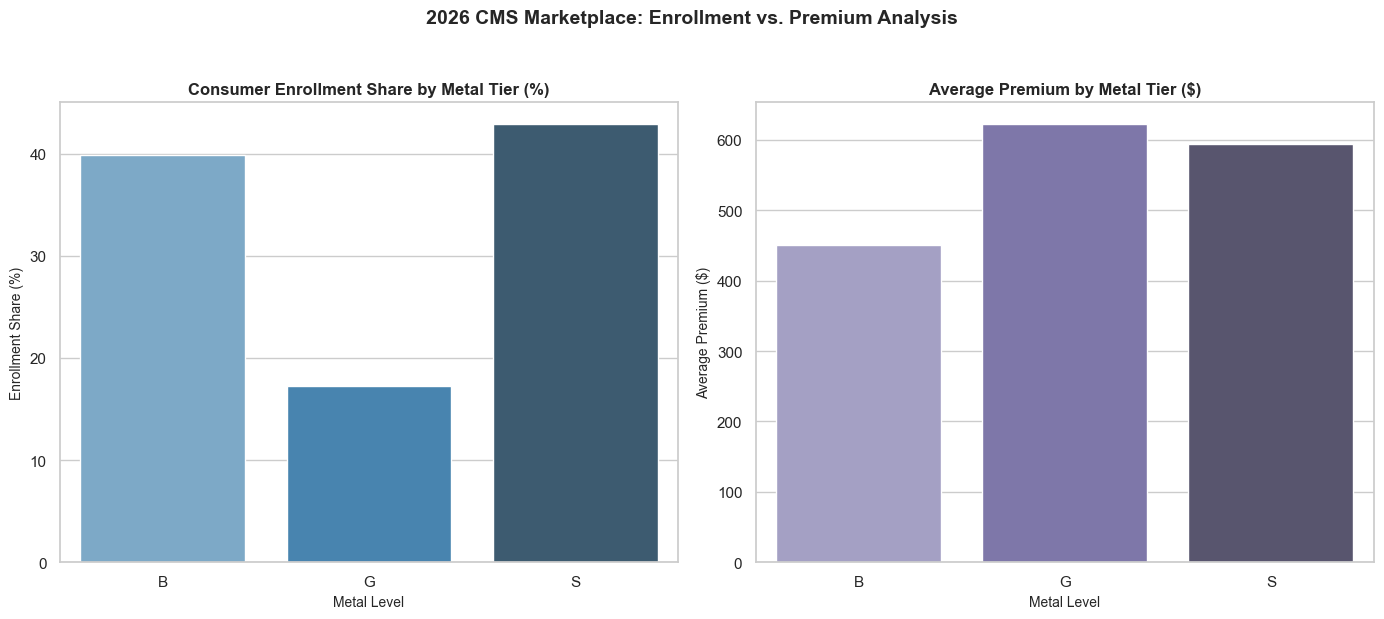

In [22]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style
sns.set_theme(style="whitegrid")
plt.rcParams.update({'figure.autolayout': True})

PROCESSED_DIR = "data/processed" if os.path.exists("data/processed") else "../data/processed"
df_master = pd.read_csv(os.path.join(PROCESSED_DIR, "master_market_analysis.csv"))

# Re-aggregate tier summary
df_tiers = df_master[df_master['Metal_Lvl'].isin(['B', 'S', 'G', 'P', 'C'])].copy()
tier_summary = df_tiers.groupby('Metal_Lvl').agg(
    Total_Enrollment=('Cnsmr', 'sum'),
    Avg_Premium=('Avg_Premium', 'mean')
).reset_index()

tier_summary['Enrollment_Share_%'] = (tier_summary['Total_Enrollment'] / tier_summary['Total_Enrollment'].sum() * 100).round(2)

# Create a figure with two subplots side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Chart 1: Enrollment Share by Metal Level
sns.barplot(
    data=tier_summary, 
    x='Metal_Lvl', 
    y='Enrollment_Share_%', 
    hue='Metal_Lvl',
    palette='Blues_d', 
    legend=False,
    ax=axes[0]
)
axes[0].set_title('Consumer Enrollment Share by Metal Tier (%)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Metal Level', fontsize=10)
axes[0].set_ylabel('Enrollment Share (%)', fontsize=10)

# Chart 2: Average Premium by Metal Level
sns.barplot(
    data=tier_summary, 
    x='Metal_Lvl', 
    y='Avg_Premium', 
    hue='Metal_Lvl',
    palette='Purples_d', 
    legend=False,
    ax=axes[1]
)
axes[1].set_title('Average Premium by Metal Tier ($)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Metal Level', fontsize=10)
axes[1].set_ylabel('Average Premium ($)', fontsize=10)

plt.suptitle('2026 CMS Marketplace: Enrollment vs. Premium Analysis', fontsize=14, fontweight='bold', y=1.03)
plt.show()

In [23]:
import os
import pandas as pd

PROCESSED_DIR = "data/processed" if os.path.exists("data/processed") else "../data/processed"
df_master = pd.read_csv(os.path.join(PROCESSED_DIR, "master_market_analysis.csv"))

# Build final executive summary table
df_tiers = df_master[df_master['Metal_Lvl'].isin(['B', 'S', 'G', 'P', 'C'])].copy()
exec_summary = df_tiers.groupby('Metal_Lvl').agg(
    Total_Enrollment=('Cnsmr', 'sum'),
    Avg_Premium=('Avg_Premium', 'mean')
).reset_index()

exec_summary['Enrollment_Share_%'] = (exec_summary['Total_Enrollment'] / exec_summary['Total_Enrollment'].sum() * 100).round(2)
exec_summary['Avg_Premium'] = exec_summary['Avg_Premium'].round(2)
exec_summary = exec_summary.sort_values(by='Total_Enrollment', ascending=False)

# Save report
report_path = os.path.join(PROCESSED_DIR, "executive_market_summary.csv")
exec_summary.to_csv(report_path, index=False)

print(f"Executive summary successfully exported to: {report_path}")
display(exec_summary)

Executive summary successfully exported to: data/processed\executive_market_summary.csv


,Metal_Lvl,Total_Enrollment,Avg_Premium,Enrollment_Share_%
2,S,29541819,594.79,42.87
0,B,27455757,450.80,39.85
1,G,11904867,622.33,17.28
